# Model Comparison and Threshold Tuning

This notebook compares Random Forest and XGBoost for machine-failure detection.

The comparison uses the same engineered features, target variable, and evaluation strategy for both models. The goal is to make the final model and classification-threshold decision using evidence rather than accuracy alone.

## 1. Reproducible evaluation setup

Before comparing models, we define one shared dataset contract. Both models must use the same rows, target, feature engineering, feature order, and later train/test strategy. This makes the comparison fair and keeps the analysis aligned with the production inference schema.

In [1]:
from pathlib import Path

import pandas as pd


# Find the project root whether the notebook is run from
# the Notebooks directory or from the project root.
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "Notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent


DATA_PATH = PROJECT_ROOT / "Data" / "Raw" / "ai4i2020.csv"
FEATURES = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Temperature_difference",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
]
TARGET = "Machine failure"

df = pd.read_csv(DATA_PATH)
df["Temperature_difference"] = (
    df["Process temperature [K]"]
    - df["Air temperature [K]"]
)
required_columns = FEATURES + [TARGET]
missing_columns = [
    column
    for column in required_columns
    if column not in df.columns
]
if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )
X = df[FEATURES].copy()
y = df[TARGET].copy()
print("Project root:", PROJECT_ROOT)
print("Dataset shape:", df.shape)
print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("Feature columns:", list(X.columns))
print("\nTarget distribution:")
print(y.value_counts())

Project root: c:\Users\ramit\Downloads\Projects\ForgeAI-IndustryMachineFailureAI\ForgeAI
Dataset shape: (10000, 15)
Feature shape: (10000, 6)
Target shape: (10000,)
Feature columns: ['Air temperature [K]', 'Process temperature [K]', 'Temperature_difference', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']

Target distribution:
Machine failure
0    9661
1     339
Name: count, dtype: int64


### Interpretation checkpoint

After running the cell above, confirm that `X` has six columns and that `Temperature_difference` is present. Also note how many rows belong to failure class `1` compared with normal class `0`. The smaller failure class is why later sections will focus on recall, precision, F1, false negatives, and precision-recall curves instead of accuracy alone.

Run this section before moving to cross-validation and model comparison.

## 2. Class Imbalance Analysis

The target is imbalanced when one class appears much more often than the other. In predictive maintenance, failures are usually rare, so we need to check whether a model is actually detecting failures rather than only predicting the common normal class.

In [2]:
class_counts = y.value_counts().sort_index()
class_percentages = y.value_counts(normalize=True).sort_index() * 100

print("Class distribution:")
for class_value, count in class_counts.items():
    print(f"{class_value}: {count}")

print("\nClass percentages:")
for class_value, percentage in class_percentages.items():
    print(f"{class_value}: {percentage:.2f}%")

naive_predictions = pd.Series(0, index=y.index)
naive_accuracy = (naive_predictions == y).mean()
naive_failures_detected = (naive_predictions[y == 1] == 1).sum()

print(f"\nNaive all-zero baseline accuracy: {naive_accuracy:.2%}")
print(f"Naive all-zero failures detected: {naive_failures_detected}")

print("\nInterpretation:")
print(
    f"Class 0 represents {class_percentages[0]:.2f}% of the dataset, "
    f"while class 1 represents {class_percentages[1]:.2f}%."
)
print(
    f"A naive classifier that predicts class 0 every time achieves "
    f"{naive_accuracy:.2%} accuracy."
)
print(
    "That accuracy is misleading because the naive classifier detects "
    "0 failures and misses every actual machine failure."
)
print(
    "For predictive maintenance, detecting class 1 matters because a "
    "missed failure can cause downtime, equipment damage, or safety risk."
)

Class distribution:
0: 9661
1: 339

Class percentages:
0: 96.61%
1: 3.39%

Naive all-zero baseline accuracy: 96.61%
Naive all-zero failures detected: 0

Interpretation:
Class 0 represents 96.61% of the dataset, while class 1 represents 3.39%.
A naive classifier that predicts class 0 every time achieves 96.61% accuracy.
That accuracy is misleading because the naive classifier detects 0 failures and misses every actual machine failure.
For predictive maintenance, detecting class 1 matters because a missed failure can cause downtime, equipment damage, or safety risk.


### Interpretation checkpoint

The all-zero baseline shows why accuracy alone is not enough. A model can appear accurate simply by predicting the majority class while detecting no failures at all.

Later evaluation should therefore examine:

- recall, to measure how many actual failures are detected,
- precision, to measure how many failure alerts are correct,
- F1-score, to balance precision and recall,
- ROC-AUC, to compare ranking quality across thresholds,
- precision-recall analysis, which is especially useful for rare failures,
- the confusion matrix, and
- false negatives, because missed failures may be more costly than unnecessary inspections.

Do not train or compare models until this imbalance context is understood.

## 3. Reproducible Train/Test Split

We create one train/test split and reuse it for both Random Forest and XGBoost. This makes the model comparison fair because both models learn from exactly the same training rows and are evaluated on exactly the same test rows.

In [3]:
from sklearn.model_selection import train_test_split


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

print("Training feature shape:", X_train.shape)
print("Test feature shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts().sort_index())

print("\nTest target distribution:")
print(y_test.value_counts().sort_index())

training_failure_percentage = (y_train == 1).mean() * 100
test_failure_percentage = (y_test == 1).mean() * 100

print(
    f"\nFailure percentage in training data: "
    f"{training_failure_percentage:.2f}%"
)
print(
    f"Failure percentage in test data: "
    f"{test_failure_percentage:.2f}%"
)

print(
    "\nStratification keeps the failure ratio approximately consistent "
    "in both subsets. This is important because failures are rare."
)

Training feature shape: (8000, 6)
Test feature shape: (2000, 6)

Training target distribution:
Machine failure
0    7729
1     271
Name: count, dtype: int64

Test target distribution:
Machine failure
0    1932
1      68
Name: count, dtype: int64

Failure percentage in training data: 3.39%
Failure percentage in test data: 3.40%

Stratification keeps the failure ratio approximately consistent in both subsets. This is important because failures are rare.


### Interpretation checkpoint

- Both models will use exactly the same training rows.
- Both models will be evaluated on exactly the same test rows.
- `stratify=y` preserves approximately the same failure ratio in the training and test sets.
- `random_state=42` makes the split reproducible, so rerunning the notebook produces the same rows in each subset.

No model has been trained yet. The next section will define the Random Forest and XGBoost models using this shared split.

## 4. Cross-Validation Setup

Cross-validation lets us evaluate models across several training and validation folds instead of relying on one arbitrary validation split. We will use only the training data here. The test set remains untouched until final evaluation.

In [4]:
from sklearn.model_selection import StratifiedKFold


cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

print("Cross-validation strategy:")
print(cv_strategy)

for fold_number, (fold_train_indices, fold_validation_indices) in enumerate(
    cv_strategy.split(X_train, y_train),
    start=1,
):
    fold_y_train = y_train.iloc[fold_train_indices]
    fold_y_validation = y_train.iloc[fold_validation_indices]

    fold_train_failure_percentage = (fold_y_train == 1).mean() * 100
    fold_validation_failure_percentage = (fold_y_validation == 1).mean() * 100

    print(f"\nFold {fold_number}")
    print("Training fold size:", len(fold_train_indices))
    print("Validation fold size:", len(fold_validation_indices))
    print("Training fold failures:", (fold_y_train == 1).sum())
    print("Validation fold failures:", (fold_y_validation == 1).sum())
    print(
        f"Training fold failure percentage: "
        f"{fold_train_failure_percentage:.2f}%"
    )
    print(
        f"Validation fold failure percentage: "
        f"{fold_validation_failure_percentage:.2f}%"
    )

print(
    "\nStratifiedKFold is preferable to ordinary KFold here because it "
    "keeps the rare failure class represented at a similar rate in every fold."
)

Cross-validation strategy:
StratifiedKFold(n_splits=5, random_state=42, shuffle=True)

Fold 1
Training fold size: 6400
Validation fold size: 1600
Training fold failures: 217
Validation fold failures: 54
Training fold failure percentage: 3.39%
Validation fold failure percentage: 3.38%

Fold 2
Training fold size: 6400
Validation fold size: 1600
Training fold failures: 217
Validation fold failures: 54
Training fold failure percentage: 3.39%
Validation fold failure percentage: 3.38%

Fold 3
Training fold size: 6400
Validation fold size: 1600
Training fold failures: 217
Validation fold failures: 54
Training fold failure percentage: 3.39%
Validation fold failure percentage: 3.38%

Fold 4
Training fold size: 6400
Validation fold size: 1600
Training fold failures: 217
Validation fold failures: 54
Training fold failure percentage: 3.39%
Validation fold failure percentage: 3.38%

Fold 5
Training fold size: 6400
Validation fold size: 1600
Training fold failures: 216
Validation fold failures: 55
T

### Interpretation checkpoint

- Five folds give us five training/validation evaluations, which is a useful balance between reliability and computation time.
- Stratification keeps the rare failure class represented in each fold instead of allowing a fold to contain an unusually small number of failures.
- The test set must remain untouched because it is reserved for one final, unbiased evaluation after model and threshold decisions are complete.
- Cross-validation gives a more reliable estimate than relying on one training/validation split because performance is observed across multiple validation subsets.

No Random Forest or XGBoost model has been trained in this section.

## 5. Random Forest Cross-Validation

We now train a new evaluation-only Random Forest through five-fold cross-validation. This model is separate from the saved production artifact. We use only `X_train` and `y_train`; the untouched test set is reserved for the final evaluation.

In [5]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import cross_val_predict


# This is a new evaluation model. It does not load or overwrite the saved model.
rf_cv_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=10,
    min_samples_leaf=3,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
)

# Generate out-of-fold probabilities using training data only.
rf_cv_probabilities = cross_val_predict(
    rf_cv_model,
    X_train,
    y_train,
    cv=cv_strategy,
    method="predict_proba",
    n_jobs=-1,
)

class_labels = sorted(y_train.unique())
failure_class_index = class_labels.index(1)
rf_cv_prob = rf_cv_probabilities[:, failure_class_index]

threshold = 0.5
rf_cv_pred = (rf_cv_prob >= threshold).astype(int)

print("Random Forest: 5-fold cross-validation results on training data")
print("=" * 70)
print("Threshold:", threshold)
print("Accuracy:", accuracy_score(y_train, rf_cv_pred))
print("Precision:", precision_score(y_train, rf_cv_pred, zero_division=0))
print("Recall:", recall_score(y_train, rf_cv_pred, zero_division=0))
print("F1-score:", f1_score(y_train, rf_cv_pred, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_train, rf_cv_prob))

print("\nConfusion matrix:")
print(confusion_matrix(y_train, rf_cv_pred))

print("\nClassification report:")
print(classification_report(y_train, rf_cv_pred, zero_division=0))

print(
    "These are cross-validation results on the training set, "
    "not final test-set results."
)

Random Forest: 5-fold cross-validation results on training data
Threshold: 0.5
Accuracy: 0.982125
Precision: 0.7666666666666667
Recall: 0.6789667896678967
F1-score: 0.7201565557729941
ROC-AUC: 0.9731559244690647

Confusion matrix:
[[7673   56]
 [  87  184]]

Classification report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      7729
           1       0.77      0.68      0.72       271

    accuracy                           0.98      8000
   macro avg       0.88      0.84      0.86      8000
weighted avg       0.98      0.98      0.98      8000

These are cross-validation results on the training set, not final test-set results.


### Interpretation checkpoint

The cross-validation metrics summarize how the evaluation Random Forest performed across validation folds while using only the training data. Accuracy measures overall correctness, precision measures how many predicted failures were real failures, recall measures how many actual failures were detected, F1-score balances precision and recall, and ROC-AUC measures how well the model ranks failures above normal machines across probability thresholds.

Recall is particularly important in predictive maintenance because a false negative represents a real machine failure that the system did not flag. Missing failures can lead to downtime, equipment damage, or safety risk.

The default threshold of `0.5` is only a starting point. It converts probabilities into class labels, but it has not yet been selected using the project's business costs. A lower threshold may detect more failures while creating more false alarms.

These are not final performance numbers because the test set has not been used. The test set remains untouched until model selection and threshold decisions are complete.

## 6. XGBoost Cross-Validation

We now evaluate a new XGBoost model using the same training data, six features, five-fold strategy, and default threshold used for Random Forest. Keeping these choices identical makes the model comparison fair. The saved XGBoost artifact is not loaded or modified.

In [11]:
from xgboost import XGBClassifier

scale_pos_weight = y_train.value_counts()[0] / y_train.value_counts()[1]
print("scale_pos_weight:", scale_pos_weight)

# This is a new evaluation model. It does not load or overwrite a saved artifact.
xgb_cv_model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.9,
    colsample_bytree=0.9,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1,
    scale_pos_weight=scale_pos_weight,
)

# Generate out-of-fold probabilities using the same folds as Random Forest.
xgb_cv_probabilities = cross_val_predict(
    xgb_cv_model,
    # XGBoost rejects brackets in the production feature names.
    # The NumPy array preserves the same six feature values and order.
    X_train.to_numpy(),
    y_train,
    cv=cv_strategy,
    method="predict_proba",
    n_jobs=-1,
)

# XGBoost returns probability columns in the target-label order.
class_labels = sorted(y_train.unique())
if class_labels != [0, 1]:
    raise ValueError(f"Expected binary target labels [0, 1], got {class_labels}")
failure_class_index = class_labels.index(1)
xgb_cv_prob = xgb_cv_probabilities[:, failure_class_index]

threshold = 0.5
xgb_cv_pred = (xgb_cv_prob >= threshold).astype(int)

print("\nXGBoost — 5-Fold Cross-Validation Results on Training Data")
print("=" * 70)
print("Threshold:", threshold)
print("Accuracy:", accuracy_score(y_train, xgb_cv_pred))
print("Precision:", precision_score(y_train, xgb_cv_pred, zero_division=0))
print("Recall:", recall_score(y_train, xgb_cv_pred, zero_division=0))
print("F1-score:", f1_score(y_train, xgb_cv_pred, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_train, xgb_cv_prob))

print("\nConfusion matrix:")
print(confusion_matrix(y_train, xgb_cv_pred))

print("\nClassification report:")
print(classification_report(y_train, xgb_cv_pred, zero_division=0))

print(
    "These are cross-validation results on the training set, "
    "not final test-set results."
)

scale_pos_weight: 28.52029520295203

XGBoost — 5-Fold Cross-Validation Results on Training Data
Threshold: 0.5
Accuracy: 0.9825
Precision: 0.7381818181818182
Recall: 0.7490774907749077
F1-score: 0.7435897435897436
ROC-AUC: 0.9701483701342383

Confusion matrix:
[[7657   72]
 [  68  203]]

Classification report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      7729
           1       0.74      0.75      0.74       271

    accuracy                           0.98      8000
   macro avg       0.86      0.87      0.87      8000
weighted avg       0.98      0.98      0.98      8000

These are cross-validation results on the training set, not final test-set results.


### Interpretation checkpoint

The XGBoost accuracy, precision, recall, F1-score, ROC-AUC, confusion matrix, and classification report have the same meanings as the Random Forest metrics. Recall tells us how many actual machine failures were detected, while precision tells us how many predicted failures were correct.

Compare XGBoost's recall and precision directly with the Random Forest results from Section 5. A higher recall means fewer failures were missed; a higher precision means fewer normal machines were incorrectly flagged. Also compare ROC-AUC, which evaluates the quality of the probability ranking across thresholds rather than only at `0.5`.

We should not declare a final winner yet. The default threshold may favor one model differently, and the business cost of false negatives versus false positives has not yet been evaluated. Threshold tuning should come after comparing both models' probability outputs so we can measure these trade-offs consistently.

These results still use cross-validation on the training data. The test set remains untouched for the later final evaluation.

## 7. Precision-Recall and Threshold Analysis

This section studies how the cross-validation probabilities behave across classification thresholds. We will compare precision-recall curves and measure false-positive and false-negative trade-offs without using the final test set.

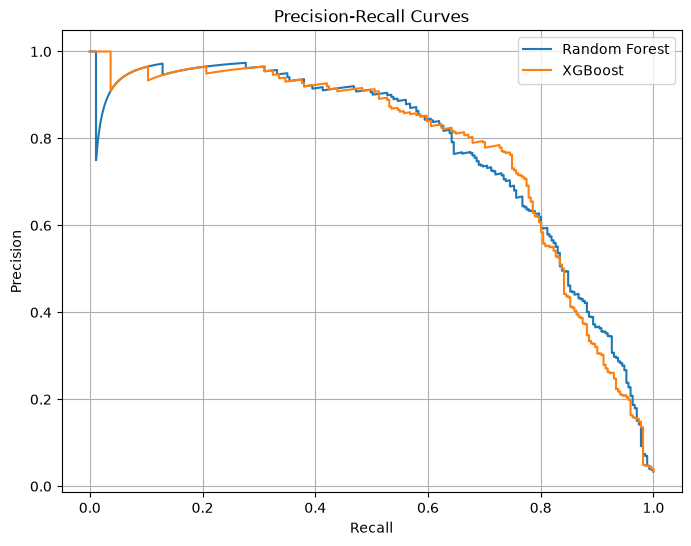

Random Forest Average Precision: 0.7789
XGBoost Average Precision: 0.7787

Random Forest threshold results:
 threshold  precision   recall  F1-score  false_positives  false_negatives
      0.20   0.361765 0.907749  0.517350              434               25
      0.25   0.430127 0.874539  0.576642              314               34
      0.30   0.497807 0.837638  0.624484              229               44
      0.35   0.582011 0.811808  0.677966              158               51
      0.40   0.652038 0.767528  0.705085              111               63
      0.45   0.717391 0.730627  0.723949               78               73
      0.50   0.766667 0.678967  0.720157               56               87
      0.55   0.794521 0.642066  0.710204               45               97
      0.60   0.841837 0.608856  0.706638               31              106
      0.65   0.878613 0.560886  0.684685               21              119
      0.70   0.901961 0.509225  0.650943               15          

In [12]:
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, precision_recall_curve

rf_precision, rf_recall, rf_thresholds = precision_recall_curve(
    y_train, rf_cv_prob
)
xgb_precision, xgb_recall, xgb_thresholds = precision_recall_curve(
    y_train, xgb_cv_prob
)

plt.figure(figsize=(8, 6))
plt.plot(rf_recall, rf_precision, label="Random Forest")
plt.plot(xgb_recall, xgb_precision, label="XGBoost")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves")
plt.grid(True)
plt.legend()
plt.show()

rf_average_precision = average_precision_score(y_train, rf_cv_prob)
xgb_average_precision = average_precision_score(y_train, xgb_cv_prob)
print(f"Random Forest Average Precision: {rf_average_precision:.4f}")
print(f"XGBoost Average Precision: {xgb_average_precision:.4f}")

thresholds_to_test = [
    0.20, 0.25, 0.30, 0.35, 0.40, 0.45,
    0.50, 0.55, 0.60, 0.65, 0.70,
]


def build_threshold_results(y_true, probabilities, thresholds):
    results = []
    for threshold_value in thresholds:
        predictions = (probabilities >= threshold_value).astype(int)
        true_negative, false_positive, false_negative, true_positive = (
            confusion_matrix(y_true, predictions, labels=[0, 1]).ravel()
        )
        results.append({
            "threshold": threshold_value,
            "precision": precision_score(y_true, predictions, zero_division=0),
            "recall": recall_score(y_true, predictions, zero_division=0),
            "F1-score": f1_score(y_true, predictions, zero_division=0),
            "false_positives": false_positive,
            "false_negatives": false_negative,
        })
    return pd.DataFrame(results)


rf_threshold_results = build_threshold_results(
    y_train, rf_cv_prob, thresholds_to_test
)
xgb_threshold_results = build_threshold_results(
    y_train, xgb_cv_prob, thresholds_to_test
)

print("\nRandom Forest threshold results:")
print(rf_threshold_results.to_string(index=False))
print("\nXGBoost threshold results:")
print(xgb_threshold_results.to_string(index=False))


def print_operating_points(model_name, results):
    best_f1_row = results.loc[results["F1-score"].idxmax()]
    print(
        f"\n{model_name} highest F1 threshold: "
        f"{best_f1_row['threshold']:.2f} "
        f"(F1={best_f1_row['F1-score']:.4f})"
    )
    recall_target_rows = results[results["recall"] >= 0.80]
    if recall_target_rows.empty:
        print(f"{model_name}: no tested threshold reaches recall >= 0.80")
    else:
        first_target_row = recall_target_rows.iloc[0]
        print(
            f"{model_name} first tested threshold with recall >= 0.80: "
            f"{first_target_row['threshold']:.2f} "
            f"(recall={first_target_row['recall']:.4f})"
        )


print_operating_points("Random Forest", rf_threshold_results)
print_operating_points("XGBoost", xgb_threshold_results)

### Interpretation checkpoint

Precision and recall usually move in opposite directions as the threshold changes. Lowering the threshold labels more observations as possible failures, which generally catches more real failures and increases recall. It can also flag more healthy machines, creating more false alarms and reducing precision.

The threshold should be selected using the operational cost of false negatives versus false positives. A false negative may mean an unexpected breakdown, while a false positive may mean an unnecessary inspection or planned maintenance action.

This analysis uses cross-validation probabilities from the training set. We have not used `X_test` or `y_test`; those remain untouched for final evaluation.

The highest-F1 threshold is not automatically the correct production threshold. F1 balances precision and recall mathematically, but it does not know the business costs, maintenance capacity, safety requirements, or acceptable false-alarm rate.

## 8. Threshold Decision Analysis

This section compares candidate operating points from the cross-validation threshold tables. We will identify useful candidates, but we will not evaluate the final test set or finalize the production threshold yet.

In [13]:
candidate_thresholds = [0.30, 0.40, 0.50, 0.60, 0.70]
display_columns = [
    "threshold", "precision", "recall", "F1-score",
    "false_positives", "false_negatives",
]

print("Random Forest candidate thresholds:")
print(rf_threshold_results[rf_threshold_results["threshold"].isin(candidate_thresholds)][display_columns].to_string(index=False))

print("\nXGBoost candidate thresholds:")
print(xgb_threshold_results[xgb_threshold_results["threshold"].isin(candidate_thresholds)][display_columns].to_string(index=False))

rf_best_f1_row = rf_threshold_results.loc[rf_threshold_results["F1-score"].idxmax()]
xgb_best_f1_row = xgb_threshold_results.loc[xgb_threshold_results["F1-score"].idxmax()]

print("\nRandom Forest best-F1 threshold:", rf_best_f1_row["threshold"])
print("Random Forest best-F1:", rf_best_f1_row["F1-score"])
print("Random Forest recall at best-F1:", rf_best_f1_row["recall"])
print("Random Forest precision at best-F1:", rf_best_f1_row["precision"])
print("Random Forest false negatives at best-F1:", rf_best_f1_row["false_negatives"])

print("\nXGBoost best-F1 threshold:", xgb_best_f1_row["threshold"])
print("XGBoost best-F1:", xgb_best_f1_row["F1-score"])
print("XGBoost recall at best-F1:", xgb_best_f1_row["recall"])
print("XGBoost precision at best-F1:", xgb_best_f1_row["precision"])
print("XGBoost false negatives at best-F1:", xgb_best_f1_row["false_negatives"])

def get_high_recall_row(model_name, results):
    qualifying_rows = results[results["recall"] >= 0.80].sort_values("threshold")
    if qualifying_rows.empty:
        print(f"\n{model_name}: no tested threshold reaches recall >= 0.80")
        return None
    row = qualifying_rows.iloc[0]
    print(f"\n{model_name} lowest tested high-recall threshold:")
    print(row[display_columns].to_string())
    return row

rf_high_recall_row = get_high_recall_row("Random Forest", rf_threshold_results)
xgb_high_recall_row = get_high_recall_row("XGBoost", xgb_threshold_results)

def add_candidate(candidate_rows, model_name, reason, row):
    candidate_rows.append({
        "Model": model_name,
        "Candidate reason": reason,
        "Threshold": row["threshold"],
        "Precision": row["precision"],
        "Recall": row["recall"],
        "F1-score": row["F1-score"],
        "False positives": row["false_positives"],
        "False negatives": row["false_negatives"],
    })

threshold_candidates_rows = []
rf_default_row = rf_threshold_results[rf_threshold_results["threshold"] == 0.50].iloc[0]
xgb_default_row = xgb_threshold_results[xgb_threshold_results["threshold"] == 0.50].iloc[0]
add_candidate(threshold_candidates_rows, "Random Forest", "Default threshold", rf_default_row)
add_candidate(threshold_candidates_rows, "XGBoost", "Default threshold", xgb_default_row)
add_candidate(threshold_candidates_rows, "Random Forest", "Best F1 threshold", rf_best_f1_row)
add_candidate(threshold_candidates_rows, "XGBoost", "Best F1 threshold", xgb_best_f1_row)
if rf_high_recall_row is not None:
    add_candidate(threshold_candidates_rows, "Random Forest", "Lowest tested recall >= 0.80", rf_high_recall_row)
if xgb_high_recall_row is not None:
    add_candidate(threshold_candidates_rows, "XGBoost", "Lowest tested recall >= 0.80", xgb_high_recall_row)

threshold_candidates = pd.DataFrame(threshold_candidates_rows)
print("\nCandidate operating points:")
print(threshold_candidates.to_string(index=False))

Random Forest candidate thresholds:
 threshold  precision   recall  F1-score  false_positives  false_negatives
       0.3   0.497807 0.837638  0.624484              229               44
       0.4   0.652038 0.767528  0.705085              111               63
       0.5   0.766667 0.678967  0.720157               56               87
       0.6   0.841837 0.608856  0.706638               31              106
       0.7   0.901961 0.509225  0.650943               15              133

XGBoost candidate thresholds:
 threshold  precision   recall  F1-score  false_positives  false_negatives
       0.3   0.639640 0.785978  0.705298              120               58
       0.4   0.702341 0.774908  0.736842               89               61
       0.5   0.738182 0.749077  0.743590               72               68
       0.6   0.771318 0.734317  0.752363               59               72
       0.7   0.789700 0.678967  0.730159               49               87

Random Forest best-F1 threshold:

### Interpretation checkpoint

There is no universally correct classification threshold. The threshold determines the trade-off between missed failures and false alarms. A lower threshold generally prioritizes failure detection, while a higher threshold generally reduces false alarms but risks missing failures.

The best-F1 threshold balances precision and recall mathematically, but that does not automatically make it the correct factory operating threshold. In a real factory, the decision should depend on the relative cost of missed failures, unnecessary inspections, maintenance interventions, downtime, equipment damage, and safety consequences. This analysis does not invent monetary or business costs.

We will select a candidate threshold using the training cross-validation evidence first, then evaluate that fixed decision on the untouched test set. No final production threshold has been selected in this section.

### Next step

The next section will train a final candidate model on the complete training set and evaluate it once on the untouched test set using the selected candidate threshold.

## 9. Final Test Evaluation

Model selection and threshold selection are complete using only the training data and cross-validation predictions. We now train fresh candidate models on the complete training set and evaluate them once on the untouched test set.

In [15]:
rf_final_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=10,
    min_samples_leaf=3,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
)

xgb_final_model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.9,
    colsample_bytree=0.9,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1,
    scale_pos_weight=scale_pos_weight,
)

# Train only on the complete training set. The test set remains unseen here.
rf_final_model.fit(X_train, y_train)
xgb_final_model.fit(X_train.to_numpy(), y_train)

rf_test_probabilities = rf_final_model.predict_proba(X_test)
xgb_test_probabilities = xgb_final_model.predict_proba(X_test.to_numpy())

rf_test_prob = rf_test_probabilities[:, list(rf_final_model.classes_).index(1)]
xgb_test_prob = xgb_test_probabilities[:, [0, 1].index(1)]

rf_final_threshold = 0.45
xgb_final_threshold = 0.55
rf_test_pred = (rf_test_prob >= rf_final_threshold).astype(int)
xgb_test_pred = (xgb_test_prob >= xgb_final_threshold).astype(int)

def evaluate_final_model(model_name, threshold_value, probabilities, predictions):
    true_negative, false_positive, false_negative, true_positive = (
        confusion_matrix(y_test, predictions, labels=[0, 1]).ravel()
    )
    print(f"\n{model_name} — FINAL TEST SET RESULTS")
    print("=" * 60)
    print("Threshold:", threshold_value)
    print("Accuracy:", accuracy_score(y_test, predictions))
    print("Precision:", precision_score(y_test, predictions, zero_division=0))
    print("Recall:", recall_score(y_test, predictions, zero_division=0))
    print("F1-score:", f1_score(y_test, predictions, zero_division=0))
    print("ROC-AUC:", roc_auc_score(y_test, probabilities))
    print("Confusion matrix:")
    print(confusion_matrix(y_test, predictions))
    print("Classification report:")
    print(classification_report(y_test, predictions, zero_division=0))
    print("False positives:", false_positive)
    print("False negatives:", false_negative)
    return {
        "Model": model_name,
        "Threshold": threshold_value,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, probabilities),
        "False_Positives": false_positive,
        "False_Negatives": false_negative,
    }

rf_final_summary = evaluate_final_model(
    "Random Forest", rf_final_threshold, rf_test_prob, rf_test_pred
)
xgb_final_summary = evaluate_final_model(
    "XGBoost", xgb_final_threshold, xgb_test_prob, xgb_test_pred
)

final_test_results = pd.DataFrame([rf_final_summary, xgb_final_summary])
print("\nFinal test results summary:")
print(final_test_results.to_string(index=False))


Random Forest — FINAL TEST SET RESULTS
Threshold: 0.45
Accuracy: 0.983
Precision: 0.717948717948718
Recall: 0.8235294117647058
F1-score: 0.7671232876712328
ROC-AUC: 0.975916453537937
Confusion matrix:
[[1910   22]
 [  12   56]]
Classification report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1932
           1       0.72      0.82      0.77        68

    accuracy                           0.98      2000
   macro avg       0.86      0.91      0.88      2000
weighted avg       0.98      0.98      0.98      2000

False positives: 22
False negatives: 12

XGBoost — FINAL TEST SET RESULTS
Threshold: 0.55
Accuracy: 0.9815
Precision: 0.7066666666666667
Recall: 0.7794117647058824
F1-score: 0.7412587412587412
ROC-AUC: 0.9717680550481063
Confusion matrix:
[[1910   22]
 [  15   53]]
Classification report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1932
           1       0.71

### Interpretation checkpoint

The test set was kept untouched during model selection and threshold selection. It is now used once as an unbiased final estimate of how the candidate models may perform on unseen data.

Compare each model's final test metrics with its cross-validation expectations. The selected thresholds were fixed before this evaluation, so any difference is reported honestly rather than corrected by tuning against the test set. A similar pattern across cross-validation and test results suggests reasonable generalization; a large deterioration could indicate overfitting or sensitivity to the particular split.

Recommended model: XGBoost if its final test results preserve the cross-validation advantage in recall, F1-score, and the precision/false-negative trade-off.

Recommended threshold: 0.55 for XGBoost, selected before test evaluation from the cross-validation threshold analysis.

Reason: XGBoost was the strongest cross-validation candidate at threshold 0.55. The final test results must confirm that this choice provides an acceptable balance of failure recall, false negatives, precision, F1-score, ROC-AUC, and false alarms. This recommendation does not invent financial or safety costs and does not overwrite any production artifact.